# Gradient Neighborhoods: profiling the pancreatic islet microenvironment

This notebook demonstrates the **gradient neighborhood** workflow in `celldega.nbhd`. From a
region of interest (ROI) we build concentric rings that step **outward** into the surrounding
tissue and **inward** into the ROI, then measure how cell-type composition and gene expression
change with distance from the ROI boundary.

Here the ROI is the set of **pancreatic islets** in a Xenium human pancreas section. We:

1. Load a pre-clustered Xenium AnnData (Leiden clusters + spatial coordinates).
2. Identify the **endocrine / islet** cluster from hormone markers.
3. Define a neighborhood per cell cluster with **alpha shapes**, then build **inward + outward
   gradient rings** around the islet neighborhood with `dega.nbhd.calc_gradient`.
4. Quantify the **cell-type proportion** and **mean hormone expression** gradient per ring.
5. Visualize the alpha shapes and rings as **static plots**, a gene **Clustergram**, and a **linked
   Landscape + Clustergram** for interactive exploration.
6. Optionally keep the rings and their results together in a `NeighborhoodCollection`.

It's a small but complete vertical slice of celldega: a dead-simple way to *define* neighborhoods
(alpha shapes), a *method* to derive new ones (gradients), neighborhood-level `AnnData` summaries
(`calc_nbhd_by_pop` / `calc_nbhd_by_gene`), and *visualization* (Landscape + Clustergram).

The dataset is the public
[`Xenium_V1_human_Pancreas_FFPE_outs.h5ad`](https://huggingface.co/datasets/broadinstitute/Celldega_Supporting_Data)
and the matching DegaFiles landscape (see the
[Scanpy-Squidpy Xenium Pancreas](../tutorial_notebooks/Scanpy-Squidpy_Xenium_Pancreas.ipynb)
tutorial for how this AnnData was produced).

In [1]:
from pathlib import Path
from urllib.parse import quote

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import scanpy as sc
from scipy import sparse
from shapely.geometry import Point

import celldega as dega


(process:92456): VIPS-WARNING **: 18:37:14.550: unable to load "/opt/homebrew/Cellar/vips/8.16.0/lib/vips-modules-8.16/vips-heif.dylib" -- dlopen(/opt/homebrew/Cellar/vips/8.16.0/lib/vips-modules-8.16/vips-heif.dylib, 0x0009): Library not loaded: /opt/homebrew/opt/x265/lib/libx265.212.dylib
  Referenced from: <CC9F0681-933C-3EE7-830D-D150B3809AD6> /opt/homebrew/Cellar/libheif/1.19.3/lib/libheif.1.19.3.dylib
  Reason: tried: '/opt/homebrew/opt/x265/lib/libx265.212.dylib' (no such file), '/System/Volumes/Preboot/Cryptexes/OS/opt/homebrew/opt/x265/lib/libx265.212.dylib' (no such file), '/opt/homebrew/opt/x265/lib/libx265.212.dylib' (no such file), '/opt/homebrew/Cellar/x265/4.2/lib/libx265.212.dylib' (no such file), '/System/Volumes/Preboot/Cryptexes/OS/opt/homebrew/Cellar/x265/4.2/lib/libx265.212.dylib' (no such file), '/opt/homebrew/Cellar/x265/4.2/lib/libx265.212.dylib' (no such file)


## 1. Load the Xenium pancreas AnnData

In [2]:
REPO_ID = "broadinstitute/Celldega_Supporting_Data"
REVISION = "main"
CACHE_DIR = Path("data/celldega_supporting_data")
H5AD_PATH = "Xenium_V1_human_Pancreas_FFPE_outs.h5ad"


def download_repo_file(repo_id, repo_path, cache_dir, revision="main"):
    cache_dir.mkdir(parents=True, exist_ok=True)
    local_path = cache_dir / Path(repo_path).name
    if local_path.exists():
        return local_path

    encoded_path = quote(repo_path)
    url = f"https://huggingface.co/datasets/{repo_id}/resolve/{revision}/{encoded_path}"
    with requests.get(url, stream=True, timeout=120) as response:
        response.raise_for_status()
        with local_path.open("wb") as handle:
            for chunk in response.iter_content(chunk_size=1024 * 1024):
                if chunk:
                    handle.write(chunk)
    return local_path


local_h5ad = download_repo_file(REPO_ID, H5AD_PATH, CACHE_DIR, REVISION)
adata = sc.read_h5ad(local_h5ad)
adata

AnnData object with n_obs × n_vars = 122678 × 377
    obs: 'cell_id', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'region', 'z_level', 'nucleus_count', 'cell_labels', 'n_counts', 'leiden'
    var: 'gene_ids', 'feature_types', 'genome', 'n_cells'
    uns: 'leiden', 'leiden_colors', 'log1p', 'neighbors', 'pca', 'spatialdata_attrs', 'umap'
    obsm: 'X_pca', 'X_umap', 'spatial'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'

In [3]:
# Xenium coordinates are in microns; make sure they live in obsm["spatial"].
def ensure_spatial_coordinates(adata):
    if "spatial" in adata.obsm:
        return
    for x_col, y_col in [("x_centroid", "y_centroid"), ("x_location", "y_location"), ("x", "y")]:
        if x_col in adata.obs and y_col in adata.obs:
            adata.obsm["spatial"] = adata.obs[[x_col, y_col]].to_numpy()
            return
    raise ValueError("The AnnData needs adata.obsm['spatial'] or x/y centroid columns.")


ensure_spatial_coordinates(adata)
spatial = adata.obsm["spatial"]

## 2. Identify the islet (endocrine) cluster

Pancreatic islets are marked by the endocrine hormones **INS** (β-cells), **GCG** (α-cells),
**SST** (δ-cells), and **PPY** (PP-cells). We score each Leiden cluster by mean hormone
expression and pick the clear winner. (In this dataset that is cluster **9** — but the score
keeps the example robust if the clustering is ever re-run and the labels change.)

In [4]:
hormones = ["INS", "GCG", "SST", "PPY"]
marker_df = sc.get.obs_df(adata, keys=[*hormones, "leiden"])
endocrine_score = marker_df.groupby("leiden", observed=True)[hormones].mean().sum(axis=1)
islet_cluster = endocrine_score.idxmax()
print(f"Islet (endocrine) cluster: {islet_cluster}")
endocrine_score.sort_values(ascending=False).round(3)

Islet (endocrine) cluster: 9


leiden
9     4.350
3     0.111
6     0.090
5     0.083
0     0.071
10    0.068
8     0.067
7     0.037
2     0.034
1     0.029
4     0.016
dtype: float32

## 3. Define neighborhoods with alpha shapes — one per cell cluster

An **alpha shape** is a concave hull that wraps a point cloud. It's a refreshingly simple way to
turn cells of a given type into a spatial neighborhood: no parameters to tune beyond a single length
scale. `dega.nbhd.alpha_shape_cell_clusters` runs this for **every** Leiden cluster at once, and
`filter_alpha_shapes` keeps a single value.

That length scale is `inv_alpha` (= 1 / alpha), and because the cell coordinates are in microns,
**`inv_alpha` is itself in microns** — it's the characteristic gap the hull is allowed to bridge.
A smaller value hugs the points tightly (more, smaller pieces); a larger value smooths over gaps.
We use a uniform `inv_alpha = 25` µm across all clusters, so each cluster becomes a **MultiPolygon**
of its spatial domains. Keeping it small means the islets stay cleanly separated rather than getting
bridged together into larger blobs.

In [5]:
INV_ALPHA = 25  # microns — uniform length scale for every cluster

gdf_alpha = dega.nbhd.alpha_shape_cell_clusters(adata, cat="leiden", alphas=[INV_ALPHA])
gdf_alpha = dega.nbhd.filter_alpha_shapes(gdf_alpha, alpha=INV_ALPHA)
gdf_alpha[["name", "cat", "area"]]

,name,cat,area
0,1,1,5.344906e+06
1,0,0,3.874089e+06
2,2,2,3.410181e+06
3,3,3,3.235656e+06
4,5,5,2.138258e+06
5,4,4,2.010451e+06
6,6,6,8.184030e+05
7,7,7,6.906917e+05
8,9,9,2.452315e+05
9,10,10,2.139498e+05


Each row is one cell-type neighborhood, so the table is already a neighborhood `GeoDataFrame`:
Celldega's neighborhood functions and widgets take it directly, without any repackaging.

In [6]:
gdf_alpha.set_index("name")[["cat", "area", "color"]]

,cat,area,color
name,,,
1,1,5.344906e+06,#ff7f0e
0,0,3.874089e+06,#1f77b4
2,2,3.410181e+06,#279e68
3,3,3.235656e+06,#d62728
5,5,2.138258e+06,#8c564b
4,4,2.010451e+06,#aa40fc
6,6,8.184030e+05,#e377c2
7,7,6.906917e+05,#b5bd61
9,9,2.452315e+05,#aec7e8


### View all cell-cluster alpha shapes on the Landscape

Passing the alpha-shape `GeoDataFrame` to `nbhd=` is all that's needed — the widget reads the
`micron_to_image_transform.csv` from the DegaFiles `base_url` and converts the micron geometry to
pixels itself, coloring each neighborhood by its cluster. Setting `landscape_state="nbhd"` reveals
the neighborhood layer in the **initial** view (the same way `landscape_state="umap"` opens on the
UMAP). The result is a tissue-wide map of every cell-type domain at a glance.

In [7]:
base_url = (
    "https://raw.githubusercontent.com/broadinstitute/"
    "celldega_Xenium_human_Pancreas_FFPE/main/"
    "Landscape_Xenium_V1_human_Pancreas_FFPE_outs_webp"
)

landscape_alpha = dega.viz.Landscape(
    technology="Xenium",
    base_url=base_url,
    height=600,
    adata=adata,
    nbhd=gdf_alpha,           # every cell-cluster alpha shape
    landscape_state="nbhd",   # show the neighborhoods on load
)

In [8]:
landscape_alpha

## 4. Build inward + outward gradient rings

From these cell-cluster neighborhoods we can derive brand-new ones. A **gradient** is anchored to
an existing neighborhood, so we pass the islet (endocrine) cluster's alpha shape to
`dega.nbhd.calc_gradient`, which grows concentric rings around it and returns a *new* neighborhood
`GeoDataFrame` — one ring per row, ordered inner-most to outer-most. We step every 50 µm in both directions, **out to
400 µm**, so the gradient reaches well into the surrounding tissue.

To stop the outward rings from overhanging into empty regions near the edges of the section, we
**clip** them to a tissue boundary. We just hand `calc_gradient` the original `adata` via
`clip_reference` — it extracts the cell coordinates and computes a tissue alpha shape on the fly, so
the caller never has to dig out spatial arrays. `clip_alpha` can be coarse (a large value such as
`200` µm) since we only need the overall tissue outline. The geometry is already in microns, so we
leave `is_pixel_space=False` (the default).

Inward erosion stops automatically once a small islet erodes away, so there are fewer inward
rings than outward ones.

In [9]:
islet_alpha = gdf_alpha[gdf_alpha["name"] == str(islet_cluster)]

gdf_grad = dega.nbhd.calc_gradient(
    islet_alpha,              # the islet neighborhood
    direction="both",         # "outward", "inward", or "both"
    bin_width=50,             # ring width in microns
    max_dist=400,             # reach well outside the islets
    clip_reference=adata,     # clip outward rings to a tissue alpha shape (from adata)
    clip_alpha=200,           # coarse tissue outline is fine
)

ring_order = list(gdf_grad["name"])
gdf_grad.set_index("name")[["direction", "dist_start_um", "dist_end_um", "area_um2"]]

,direction,dist_start_um,dist_end_um,area_um2
name,,,,
in (-50~-100) µm,inward,-100,-50,5.206802e+03
in (0~-50) µm,inward,-50,0,2.400247e+05
out (+0~+50) µm,outward,0,50,9.692823e+05
out (+50~+100) µm,outward,50,100,1.333965e+06
out (+100~+150) µm,outward,100,150,1.460663e+06
out (+150~+200) µm,outward,150,200,1.526652e+06
out (+200~+250) µm,outward,200,250,1.497779e+06
out (+250~+300) µm,outward,250,300,1.414924e+06
out (+300~+350) µm,outward,300,350,1.232885e+06


### Static plot — islets and their gradient rings

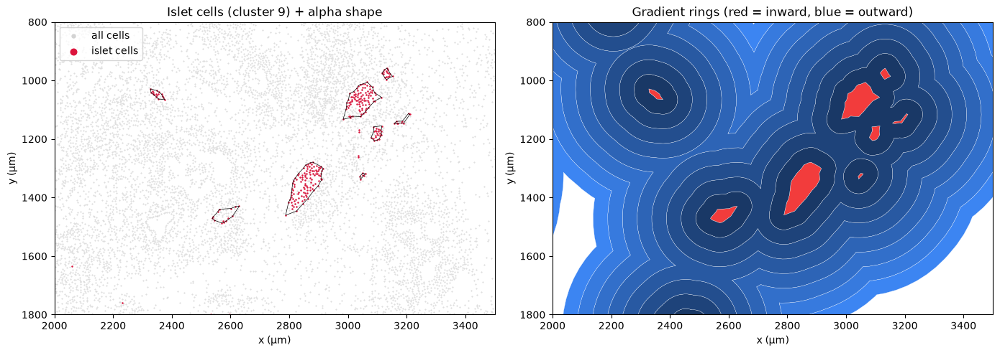

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: islet cells + the islet cluster's alpha-shape outline.
islet_points = spatial[(adata.obs["leiden"] == islet_cluster).to_numpy()]
islet_shape = islet_alpha.geometry.iloc[0]
axes[0].scatter(spatial[:, 0], spatial[:, 1], s=0.2, color="lightgray", label="all cells")
axes[0].scatter(islet_points[:, 0], islet_points[:, 1], s=0.6, color="crimson", label="islet cells")
gpd.GeoSeries([islet_shape]).boundary.plot(ax=axes[0], color="black", linewidth=0.5)
axes[0].set_title(f"Islet cells (cluster {islet_cluster}) + alpha shape")
axes[0].legend(markerscale=8, loc="upper left")

# Right: gradient rings, colored inward (reds) -> outward (blues).
gdf_grad.plot(ax=axes[1], color=gdf_grad["color"], edgecolor="white", linewidth=0.2)
axes[1].set_title("Gradient rings (red = inward, blue = outward)")

for ax in axes:
    ax.set_aspect("equal")
    ax.set_xlim(2000, 3500)   # zoom to an islet-rich region
    ax.set_ylim(1800, 800)
    ax.set_xlabel("x (µm)")
    ax.set_ylabel("y (µm)")
fig.tight_layout()

## 5. Quantify the gradient

Because the rings are a neighborhood `GeoDataFrame`, the `calc_nbhd_by_*` functions summarize
each ring directly, returning rings × features `AnnData`:

- `calc_nbhd_by_pop` → cell-type **proportion** per ring (here, the islet-cell fraction).
- `calc_nbhd_by_gene` → **mean expression** per ring (here, the islet hormones).

Rings with fewer than 5 cells have no estimate; we reindex to every ring (filling them with 0)
so the gradient axis stays complete.

In [11]:
ring_population = dega.nbhd.calc_nbhd_by_pop(
    adata, gdf_grad, category="leiden", output="proportion", min_cells=5
)
ring_expression = dega.nbhd.calc_nbhd_by_gene(gdf_grad, "cell", adata, min_cells=5)


def ring_frame(adata_rings):
    X = adata_rings.X.toarray() if sparse.issparse(adata_rings.X) else np.asarray(adata_rings.X)
    frame = pd.DataFrame(X, index=adata_rings.obs_names, columns=adata_rings.var_names)
    return frame.reindex(ring_order).fillna(0)


proportion = ring_frame(ring_population)
expression = ring_frame(ring_expression)
rings = gdf_grad.set_index("name")

summary = pd.DataFrame({
    "direction": rings["direction"].reindex(ring_order),
    "dist_start_um": rings["dist_start_um"].reindex(ring_order),
    "islet_proportion": proportion[islet_cluster],
    **{f"{g}_mean": expression[g] for g in hormones if g in expression.columns},
})
summary.round(3)

,direction,dist_start_um,islet_proportion,INS_mean,GCG_mean,SST_mean,PPY_mean
in (-50~-100) µm,inward,-100,1.000,2.609,1.760,1.376,0.000
in (0~-50) µm,inward,-50,0.860,1.761,1.602,0.752,0.048
out (+0~+50) µm,outward,0,0.045,0.201,0.222,0.071,0.014
out (+50~+100) µm,outward,50,0.001,0.032,0.028,0.013,0.004
out (+100~+150) µm,outward,100,0.001,0.018,0.015,0.007,0.002
out (+150~+200) µm,outward,150,0.001,0.013,0.012,0.008,0.002
out (+200~+250) µm,outward,200,0.000,0.009,0.007,0.004,0.004
out (+250~+300) µm,outward,250,0.000,0.007,0.007,0.004,0.002
out (+300~+350) µm,outward,300,0.000,0.005,0.006,0.006,0.002
out (+350~+400) µm,outward,350,0.000,0.006,0.005,0.002,0.002


### Static plots — composition and expression vs. distance from the islet edge

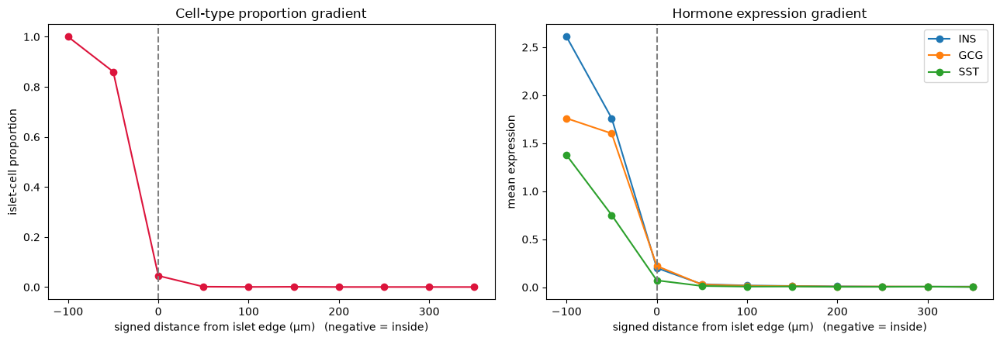

In [12]:
x = rings["dist_start_um"].reindex(ring_order).astype(float).to_numpy()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(x, proportion[islet_cluster].to_numpy(), "o-", color="crimson")
axes[0].axvline(0, ls="--", color="gray")
axes[0].set_title("Cell-type proportion gradient")
axes[0].set_ylabel("islet-cell proportion")

for gene in ["INS", "GCG", "SST"]:
    axes[1].plot(x, expression[gene].to_numpy(), "o-", label=gene)
axes[1].axvline(0, ls="--", color="gray")
axes[1].set_title("Hormone expression gradient")
axes[1].set_ylabel("mean expression")
axes[1].legend()

for ax in axes:
    ax.set_xlabel("signed distance from islet edge (µm)   (negative = inside)")
fig.tight_layout()

Both readouts fall off sharply right at the islet boundary (distance 0): islet cells and
their hormones are essentially confined to the ROI, with a thin spillover into the first
outward ring before the surrounding acinar tissue takes over.

## 6. Clustergram of the gradient gene feature space

The neighborhood-by-gene `AnnData` is a matrix of **rings × genes**, so we can cluster it as a
heatmap to see which genes share a gradient profile. We keep the 40 most variable genes across the
rings, transpose to **genes × rings**, and build a `dega.clust.Matrix` (row-z-scored) and a
`Clustergram`. We set `col_entity="nbhd"` so the columns (rings) can link to the Landscape in the
next section. Genes separate into an islet-enriched block (high inside, e.g. INS / GCG / SST) and an
acinar block (high outside), while the rings order into an inward vs. outward split. (We build the
`Clustergram` here and display it linked with the Landscape below.)

In [13]:
gene_frame = ring_frame(ring_expression)
top_variable_genes = gene_frame.var(axis=0).sort_values(ascending=False).head(40).index
gradient_gene_matrix = gene_frame[top_variable_genes].T   # genes (rows) x rings (cols)

mat = dega.clust.Matrix(gradient_gene_matrix, row_entity="gene", col_entity="nbhd")
mat.norm(axis="row", by="zscore")
mat.cluster()

cgm = dega.viz.Clustergram(matrix=mat, width=500, height=500)

## 7. Linked Landscape + Clustergram

`dega.viz.landscape_clustergram` places the gradient `Landscape` and the `Clustergram` side by side
and **links** them. Passing `nbhd=gdf_grad` is all the Landscape needs — it converts the micron ring
geometry to pixels using the DegaFiles transform, each ring keeps its gradient `color` (reds inward,
blues outward), and `landscape_state="nbhd"` shows the rings on load.

Because the clustergram's columns are the gradient rings (`col_entity="nbhd"`) and the Landscape's
neighborhood names are the same ring labels, clicking a ring **column** in the heatmap highlights
that ring on the tissue (and toggles on the NBHD layer) — letting you read expression and spatial
position together.

In [14]:
landscape_grad = dega.viz.Landscape(
    technology="Xenium",
    base_url=base_url,
    height=600,
    adata=adata,
    nbhd=gdf_grad,            # the gradient rings
    landscape_state="nbhd",   # show the rings on load
)

linked = dega.viz.landscape_clustergram(landscape_grad, cgm)

In [15]:
linked

## 8. Optional: keep the results together in a `NeighborhoodCollection`

Everything above used plain objects: a `GeoDataFrame` of rings and the `AnnData` results. When
you want the rings, their per-ring tables, and ring-to-ring relations kept aligned in one object
(to save them together, or to subset them all at once), store them in a `NeighborhoodCollection`.

The collection only stores data. The `celldega.nbhd` functions do the computation and return
plain objects, which we store with `add_mod` (per-ring tables) and `add_relation` (ring-to-ring
matrices). Rings that fell below `min_cells` are zero-filled on the collection's ring axis.

In [16]:
nc_grad = dega.nbhd.NeighborhoodCollection(gdf=gdf_grad, nbhd_type="gradient")
nc_grad.add_mod("population", ring_population)
nc_grad.add_mod("gene", ring_expression)
nc_grad.add_relation("bordering", dega.nbhd.calc_nbhd_bordering(nc_grad, metric="binary"))
nc_grad.mdata

MuData object with n_obs × n_vars = 10 × 388
  obs:	'neighborhood_id', 'name', 'ring_range_um', 'direction', 'dist_start_um', 'dist_end_um', 'area_um2', 'area_px2', 'area', 'color', 'neighborhood_type', 'method', 'centroid_x', 'centroid_y'
  var:	'entity_type', 'leiden', 'color'
  uns:	'celldega'
  obsp:	'bordering'
  2 modalities
    population:	10 x 11
      obs:	'neighborhood_id', 'name', 'ring_range_um', 'direction', 'dist_start_um', 'dist_end_um', 'area_um2', 'area_px2', 'area', 'color', 'neighborhood_type', 'method', 'centroid_x', 'centroid_y', 'n_cells', 'leiden'
      var:	'leiden', 'entity_type', 'color'
      uns:	'category', 'output', 'axis_entities', 'leiden_colors'
    gene:	10 x 377
      obs:	'neighborhood_id', 'name', 'ring_range_um', 'direction', 'dist_start_um', 'dist_end_um', 'area_um2', 'area_px2', 'area', 'color', 'neighborhood_type', 'method', 'centroid_x', 'centroid_y', 'n_cells'
      var:	'entity_type'
      uns:	'by', 'axis_entities', 'nbhd_colors'

The functions also accept the collection wherever they take a neighborhood `GeoDataFrame`, and so
do `Landscape(nbhd=nc_grad)` and `dega.clust.Matrix(mdata=nc_grad, color_by="population")`.
Computing the population table from the collection gives the same result, and the stored table
reads back on the full ring axis:

In [17]:
pop_from_nc = dega.nbhd.calc_nbhd_by_pop(
    adata, nc_grad, category="leiden", output="proportion", min_cells=5
)
assert np.allclose(pop_from_nc.to_df(), ring_population.to_df())

nc_grad.mod["population"].to_df().loc[ring_order, [islet_cluster]].T.round(3)

neighborhood_id,in (-50~-100) µm,in (0~-50) µm,out (+0~+50) µm,out (+50~+100) µm,out (+100~+150) µm,out (+150~+200) µm,out (+200~+250) µm,out (+250~+300) µm,out (+300~+350) µm,out (+350~+400) µm
leiden,,,,,,,,,,
9,1.0,0.86,0.045,0.001,0.001,0.001,0.0,0.0,0.0,0.0
